In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.feature_selection import VarianceThreshold
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
import joblib

In [2]:
df = pd.read_csv('sleep_health_dataset.csv')

X = df.drop(['felt_rested', 'sleep_disorder_risk', 'cognitive_performance_score', 'person_id', 'country', 'occupation'], axis=1)
y = df['felt_rested'].astype('category')

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [3]:
print(X_train.select_dtypes(include=['category', 'object']).columns)
print(X_train.select_dtypes(include=['number']).columns)

Index(['gender', 'chronotype', 'mental_health_condition', 'season',
       'day_type'],
      dtype='object')
Index(['age', 'bmi', 'sleep_duration_hrs', 'sleep_quality_score',
       'rem_percentage', 'deep_sleep_percentage', 'sleep_latency_mins',
       'wake_episodes_per_night', 'caffeine_mg_before_bed',
       'alcohol_units_before_bed', 'screen_time_before_bed_mins',
       'exercise_day', 'steps_that_day', 'nap_duration_mins', 'stress_score',
       'work_hours_that_day', 'heart_rate_resting_bpm', 'sleep_aid_used',
       'shift_work', 'room_temperature_celsius', 'weekend_sleep_diff_hrs'],
      dtype='object')


Target Variable: 'felt_rested' (Binary Classification)
Other available target variables: 'sleep_disorder_risk', 'cognitive_performance_score' (will ignore)
Troublesome columns: 'person_id', 'country', 'occupation' (will ignore)

Total Features (before categorical encoding): 25

In [4]:
print(X_train.shape)

(80000, 26)


In [5]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 80000 entries, 75220 to 15795
Data columns (total 26 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   age                          80000 non-null  int64  
 1   gender                       80000 non-null  object 
 2   bmi                          80000 non-null  float64
 3   sleep_duration_hrs           80000 non-null  float64
 4   sleep_quality_score          80000 non-null  float64
 5   rem_percentage               80000 non-null  float64
 6   deep_sleep_percentage        80000 non-null  float64
 7   sleep_latency_mins           80000 non-null  int64  
 8   wake_episodes_per_night      80000 non-null  int64  
 9   caffeine_mg_before_bed       80000 non-null  int64  
 10  alcohol_units_before_bed     80000 non-null  float64
 11  screen_time_before_bed_mins  80000 non-null  int64  
 12  exercise_day                 80000 non-null  int64  
 13  steps_that_day   

In [6]:
X_train.describe()

,age,bmi,sleep_duration_hrs,sleep_quality_score,rem_percentage,deep_sleep_percentage,sleep_latency_mins,wake_episodes_per_night,caffeine_mg_before_bed,alcohol_units_before_bed,...,exercise_day,steps_that_day,nap_duration_mins,stress_score,work_hours_that_day,heart_rate_resting_bpm,sleep_aid_used,shift_work,room_temperature_celsius,weekend_sleep_diff_hrs
count,80000.000000,80000.000000,80000.000000,80000.000000,80000.000000,80000.000000,80000.000000,80000.000000,80000.0000,80000.000000,...,80000.000000,80000.000000,80000.000000,80000.000000,80000.000000,80000.000000,80000.000000,80000.000000,80000.000000,80000.000000
mean,34.697137,26.292440,6.422830,4.868117,20.247071,20.259398,19.834050,3.347138,38.8455,0.595875,...,0.451300,7499.353275,14.905862,5.733574,7.143869,66.572963,0.560037,0.084062,20.529151,1.198910
std,11.036963,4.474497,1.273521,1.504346,3.410407,4.258976,7.587592,1.919663,69.5390,1.057437,...,0.497626,3463.018663,21.393009,1.617895,3.475819,7.231380,0.496386,0.277483,2.902077,0.786988
min,18.000000,16.000000,3.000000,1.000000,10.000000,5.000000,1.000000,0.000000,0.0000,0.000000,...,0.000000,500.000000,0.000000,1.000000,0.000000,45.000000,0.000000,0.000000,15.000000,-1.000000
25%,26.000000,23.200000,5.530000,3.800000,18.000000,17.400000,14.000000,2.000000,0.0000,0.000000,...,0.000000,5042.000000,0.000000,4.800000,4.800000,62.000000,0.000000,0.000000,18.500000,0.670000
50%,33.000000,26.300000,6.360000,4.900000,20.300000,20.300000,19.000000,3.000000,0.0000,0.000000,...,0.000000,7442.000000,0.000000,5.800000,7.400000,67.000000,1.000000,0.000000,20.500000,1.200000
75%,42.000000,29.300000,7.270000,6.000000,22.600000,23.200000,25.000000,5.000000,80.0000,1.000000,...,1.000000,9887.000000,30.000000,6.800000,9.700000,71.000000,1.000000,0.000000,22.500000,1.740000
max,69.000000,45.000000,10.500000,10.000000,30.000000,30.000000,58.000000,8.000000,400.0000,6.000000,...,1.000000,20000.000000,116.000000,10.000000,18.000000,99.000000,1.000000,1.000000,28.000000,3.000000


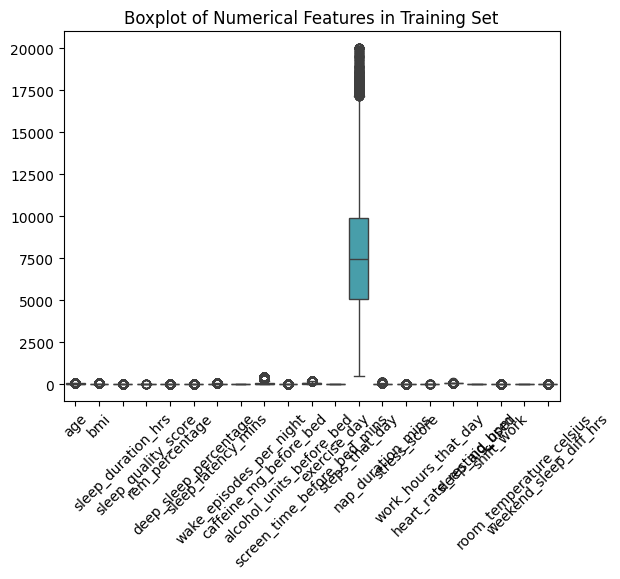

In [7]:
sns.boxplot(data=X_train.select_dtypes(include=['number']))
plt.title('Boxplot of Numerical Features in Training Set')
plt.xticks(rotation=45)
plt.show()

Need to scale to stop variable from having larger weight in training + check outliers

Need to encode categorical variables using one hot encoding to allow for use in svm

In [8]:
def preprocess_train(X, y):
    df = X.copy()
    y = y.copy()

    for col in df.columns:
        if df[col].dtype == 'object':
            df[col] = df[col].astype('category')

    # Outlier removal
    NUMERIC_COLS = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
    NUMERIC_COLS.remove('shift_work')

    Q1 = df[NUMERIC_COLS].quantile(0.25)
    Q3 = df[NUMERIC_COLS].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    mask = pd.Series(True, index=df.index)
    for col in NUMERIC_COLS:
        mask &= (df[col] >= lower_bound[col]) & (df[col] <= upper_bound[col])

    df = df[mask]
    y = y[mask]

    # Encoding
    df = pd.get_dummies(df, drop_first=True)
    train_columns = df.columns

    # Scaling
    scaler = StandardScaler()
    df[NUMERIC_COLS] = scaler.fit_transform(df[NUMERIC_COLS])

    return df, y, scaler, train_columns

Separate cleaning for training and test to prevent data leakage

In [9]:
def preprocess_test(X, y, scaler, train_columns):
    df = X.copy()
    y = y.copy()

    for col in df.columns:
        if df[col].dtype == 'object':
            df[col] = df[col].astype('category')

    NUMERIC_COLS = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
    NUMERIC_COLS.remove('shift_work')

    df = pd.get_dummies(df, drop_first=True)
    df = df.reindex(columns=train_columns, fill_value=0)

    df[NUMERIC_COLS] = scaler.transform(df[NUMERIC_COLS])

    return df, y

In [10]:
X_train_prep, y_train, scaler, train_cols = preprocess_train(X_train, y_train)
X_test_prep, y_test = preprocess_test(X_test, y_test, scaler, train_cols)

In [11]:
print(X_train_prep.shape)
print(X_test_prep.shape)

(63153, 32)
(20000, 32)


After encoding and preprocessing, number of features is now 32, will fix in DR phase

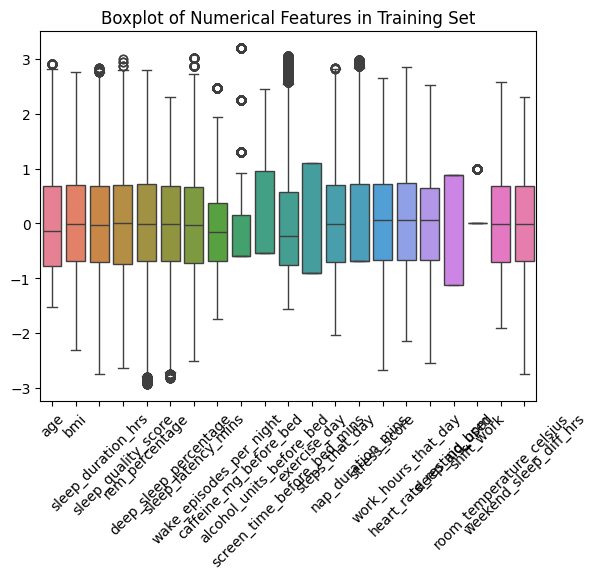

In [12]:
sns.boxplot(data=X_train_prep.select_dtypes(include=['number']))
plt.title('Boxplot of Numerical Features in Training Set')
plt.xticks(rotation=45)
plt.show()

Data has been scaled, outliers removed but other appear but its ok, will assume they are just extreme values

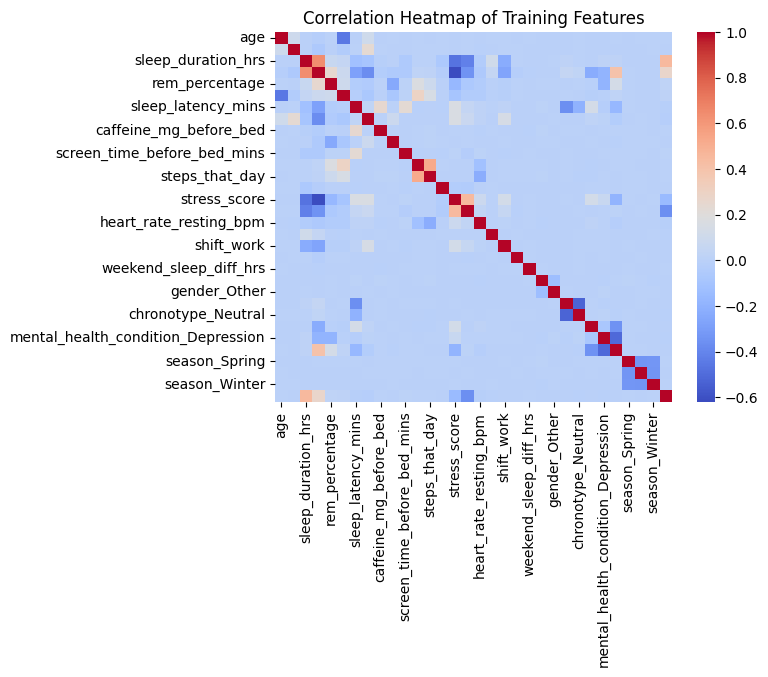

In [13]:
sns.heatmap(X_train_prep.corr(), cmap='coolwarm')
plt.title('Correlation Heatmap of Training Features')
plt.show()

Negligble multicollinearity

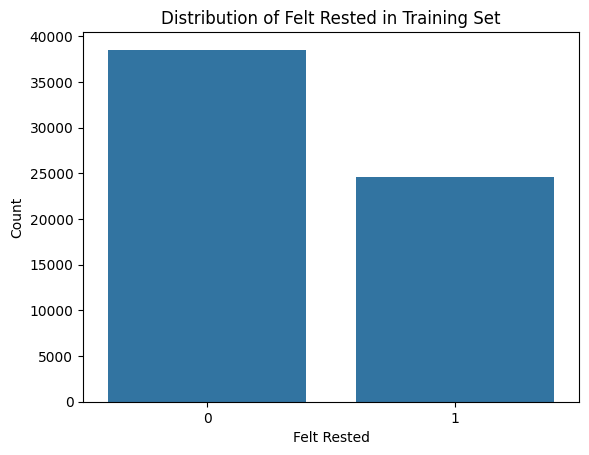

In [14]:
sns.countplot(x=y_train)
plt.title('Distribution of Felt Rested in Training Set')
plt.xlabel('Felt Rested')
plt.ylabel('Count')
plt.show()

Class Labels imbalanced 

In [15]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train_prep, y_train)

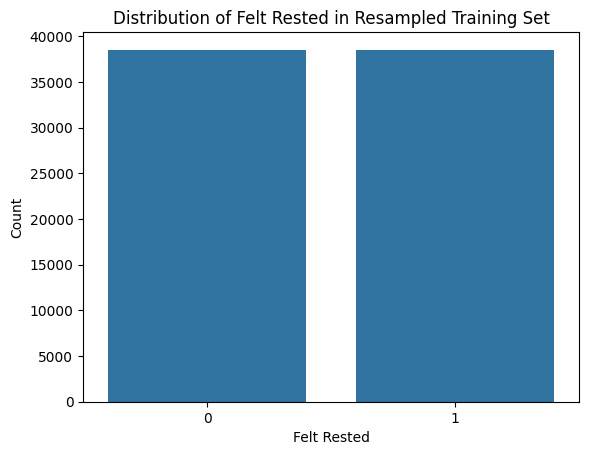

In [16]:
sns.countplot(x=y_train_res)
plt.title('Distribution of Felt Rested in Resampled Training Set')
plt.xlabel('Felt Rested')
plt.ylabel('Count')
plt.show()

Dimensionality Reduction Techniques that will be used: Variance Threshold and PCA

In [17]:
X_train_res.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 77024 entries, 0 to 77023
Data columns (total 32 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   age                                 77024 non-null  float64
 1   bmi                                 77024 non-null  float64
 2   sleep_duration_hrs                  77024 non-null  float64
 3   sleep_quality_score                 77024 non-null  float64
 4   rem_percentage                      77024 non-null  float64
 5   deep_sleep_percentage               77024 non-null  float64
 6   sleep_latency_mins                  77024 non-null  float64
 7   wake_episodes_per_night             77024 non-null  float64
 8   caffeine_mg_before_bed              77024 non-null  float64
 9   alcohol_units_before_bed            77024 non-null  float64
 10  screen_time_before_bed_mins         77024 non-null  float64
 11  exercise_day                        77024

Will now build pipeline that performs the DR techniques and trains SVM while optimizing hyperparameters

In [18]:
svm_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('variance_threshold', VarianceThreshold(threshold=0.1)),
    ('pca', PCA(n_components=0.95)),
    ('svm', SVC())
])

param_grid = {
    'svm__C': [0.1, 1, 10],
    'svm__kernel': ['rbf', 'poly'],
}

print("Running GridSearchCV...")
grid_search = GridSearchCV(
    svm_pipeline,
    param_grid,
    scoring='accuracy',
    cv=5,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train_res, y_train_res)

Running GridSearchCV...
Fitting 5 folds for each of 6 candidates, totalling 30 fits


GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('variance_threshold',
                                        VarianceThreshold(threshold=0.1)),
                                       ('pca', PCA(n_components=0.95)),
                                       ('svm', SVC())]),
             n_jobs=-1,
             param_grid={'svm__C': [0.1, 1, 10],
                         'svm__kernel': ['rbf', 'poly']},
             scoring='accuracy', verbose=1)

In [19]:
print(f"\nBest parameters: {grid_search.best_params_}")
print(f"Best CV score: {grid_search.best_score_:.2f}")

best_model = grid_search.best_estimator_
best_test_acc = best_model.score(X_test_prep, y_test)
print(f"Best test accuracy: {best_test_acc:.2f}")


Best parameters: {'svm__C': 10, 'svm__kernel': 'rbf'}
Best CV score: 0.75
Best test accuracy: 0.70


Model with best test accuracy is dumped to file to avoid retraining everytime

In [20]:
joblib.dump(best_model, 'svm_pipeline_model_final.joblib')
print("Model saved to 'svm_pipeline_model_final.joblib'")

Model saved to 'svm_pipeline_model_final.joblib'


In [21]:
from sklearn.metrics import classification_report, confusion_matrix
y_pred = best_model.predict(X_test_prep)
print("Classification Report:")
print(classification_report(y_test, y_pred))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.72      0.75     12132
           1       0.61      0.69      0.65      7868

    accuracy                           0.70     20000
   macro avg       0.70      0.70      0.70     20000
weighted avg       0.71      0.70      0.71     20000

Confusion Matrix:
[[8689 3443]
 [2462 5406]]


<Axes: >

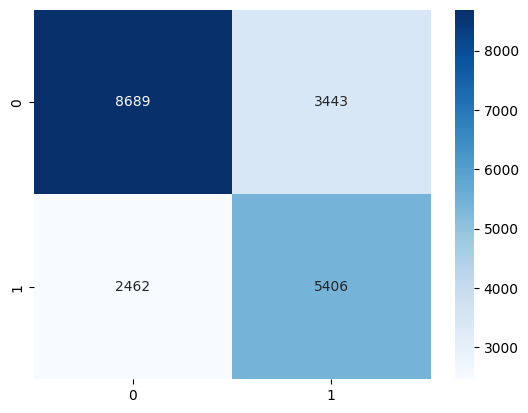

In [22]:
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')